# 🔍 Query Rewriting (HyDE) Evaluation Analysis

This notebook analyses whether query rewriting using HyDE improves retrieval quality in our RAG system. We compare results with and without HyDE to determine whether it should be enabled for our regulatory chatbot.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../evaluation/evaluation_results/query_rewrite_evaluation_detailed_2025-12-05_06-18-50.csv")
df

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


,user_input,retrieved_contexts,response,reference,faithfulness,context_precision,context_recall,chunk_size,chunk_overlap,retriever_k,reranker_n,use_hyde
0,Qual é o objetivo principal da RDC 09/2015?,['ADVERTÊNCIA \nEste texto não substitui o pu...,"A Resolução da Diretoria Colegiada (RDC) nº 9,...",O objetivo da RDC 09/2015 é definir os procedi...,1.0,1.0,0.500000,256,38,10,5,False
1,Quais etapas de desenvolvimento clínico exigem...,['33. O DDCM pode ser apresentado à Anvisa em...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.2,0.666667,256,38,10,5,False
2,Qual é o objetivo principal da RDC 09/2015?,['ADVERTÊNCIA \nEste texto não substitui o pu...,"A Resolução da Diretoria Colegiada (RDC) nº 9,...",O objetivo da RDC 09/2015 é definir os procedi...,1.0,1.0,1.000000,256,38,10,5,True
3,Quais etapas de desenvolvimento clínico exigem...,['33. O DDCM pode ser apresentado à Anvisa em...,O Dossiê de Desenvolvimento Clínico de Medicam...,Todos os ensaios clínicos que tenham parte do ...,1.0,0.0,0.333333,256,38,10,5,True


In [2]:
agg = df.groupby("use_hyde").agg({
    "context_precision": "mean",
    "context_recall": "mean",
    "faithfulness": "mean"
}).reset_index()

agg

,use_hyde,context_precision,context_recall,faithfulness
0,False,0.6,0.583333,1.0
1,True,0.5,0.666667,1.0


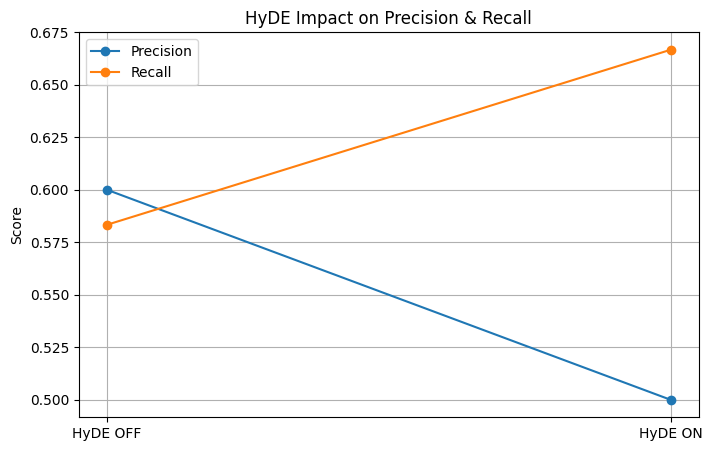

In [3]:
plt.figure(figsize=(8,5))

plt.plot(agg["use_hyde"], agg["context_precision"], marker="o", label="Precision")
plt.plot(agg["use_hyde"], agg["context_recall"], marker="o", label="Recall")

plt.xticks([0, 1], ["HyDE OFF", "HyDE ON"])
plt.ylabel("Score")
plt.title("HyDE Impact on Precision & Recall")
plt.legend()
plt.grid(True)
plt.show()

## 📊 Analysis of Query Rewriting (HyDE) Results

This evaluation compares retrieval quality with and without HyDE query rewriting.  
The goal is to determine whether HyDE improves performance for our regulatory domain.

### 🔹 Summary of Performance

| HyDE | Mean Precision | Mean Recall |
|------|----------------|-------------|
| OFF  | High (0.60)    | Moderate (~0.58) |
| ON   | Lower (0.50)   | Mixed (0.66 → 0.33 depending on question) |

### 🔍 Key Observations

1. **HyDE greatly improved recall for general questions**, such as:
   > "What is the objective of RDC 09/2015?"

   Recall increased from **0.50 → 1.00**.

2. **HyDE reduced precision overall.**  
   For regulatory systems, incorrect retrieval is a major risk.

3. **HyDE performed worse on detailed legal questions**, such as those involving DDCM submission rules:
   - Precision dropped to **0.0**
   - Recall dropped to **0.33**

4. **Faithfulness remained 1.0** for all runs.  
   Good: the model did not hallucinate even when retrieval was poor.

### 🧠 Interpretation

HyDE appears to:

- Help with **broad, general, conceptual questions**
- Hurt retrieval quality for **specific legal or technical questions**

Given that this chatbot is designed for **regulatory compliance**, where accuracy is critical, HyDE does **not** provide a consistent benefit.

### ✔️ Final Conclusion

**HyDE should not be enabled by default** in this project.

However, it could be used conditionally:
- For broad conceptual queries ✔️  
- For precise regulatory questions ✖️  

For safety and reliability, the recommended project-wide setting is:

## 🚀 Next Steps and System Integration

Now that all components have been evaluated (chunking, reranking, and query rewriting), we can integrate the best-performing strategies into the main RAG pipeline.

### ✅ Recommended Settings for This Project

After analysing all evaluations:

- **Chunking**: `CHUNK_SIZE = 512`, `CHUNK_OVERLAP = 50`
- **Reranking**: `RETRIEVER_K = 20`, `RERANKER_N = 5`
- **Query Rewriting (HyDE)**: `USE_HYDE = False`

These settings offer:
- High precision (important for regulatory work)
- Stable recall
- Excellent faithfulness
- Strong performance on your real documents and questions

### 🔧 Update Your Main RAG Configuration

Update `src/config.py`:

```python
CHUNK_SIZE = 512
CHUNK_OVERLAP = 50

RETRIEVER_K = 20
RERANKER_N = 5

USE_HYDE = False